## Background

Following the strikes on Iran in February 2026 and the subsequent blockade of the Strait of Hormuz, oil prices shot up globally and greatly affected the general public. The sharp, erratic price moves of Brent crude oil in particular during this period enticed me to dig deeper quantitatively as I wanted to see if different price behaviours could be shown quantitatively and tested against a simple baseline strategy. 

That is what this project outlines: starting with a simple baseline strategy (moving average crossovers), before testing whether regime-switching models such as GBM (Geometric Brownian Motion) and OU (Ornstein-Uhlenbeck) processes improve upon that baseline. The contrasting behaviour of the two models is the key idea I aim to interpret: GBM for consistent price movements and OU for mean-reversion. Comparing both gives a simple way to test whether switching between different behaviour types outperforms a basic strategy.


## Question 

Can regime-switching models outperform a single moving average crossover strategy on Brent crude?

# Data 

We first pull the raw Brent crude price data (since 2016) using yfinance, where the BZ=F ticker represents Brent Crude Oil futures. This is to examine the historical behaviour of Brent crude that subsequently determines the modelling approaches we could use, instead of choosing GBM and OU for the sake of it, and the approximate decade-long window gives enough data to work with. We then plot the Close prices to visualise the price behaviour.

In [ ]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt # import relevant libraries 

brent = yf.download('BZ=F', start='2016-01-01', end='2026-08-23') # pull price data
brent.columns = brent.columns.droplevel(1) # remove redunant ticker 
brent.head()

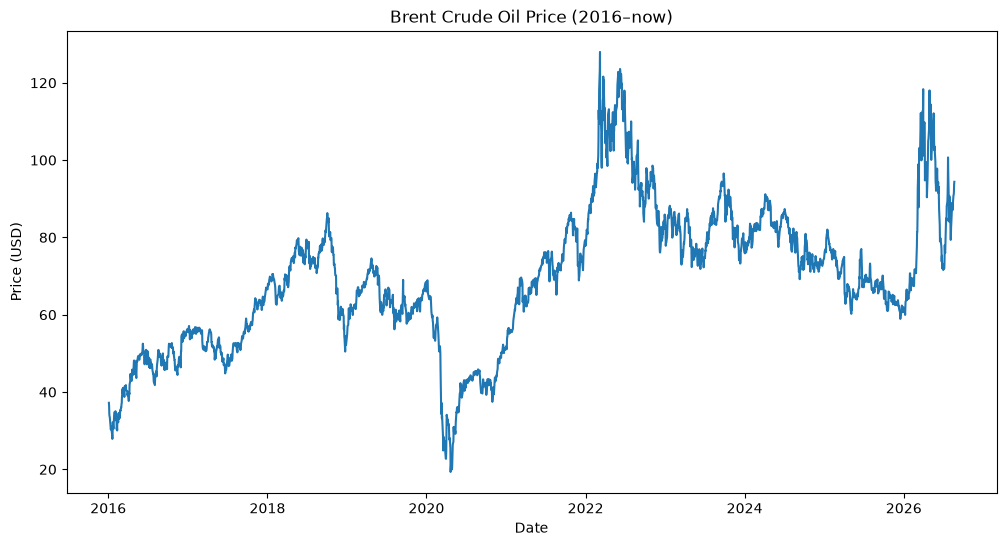

In [18]:
plt.figure(figsize=(12, 6))
plt.plot(brent.index, brent['Close'])
plt.title('Brent Crude Oil Price (2016–now)')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.show()

From the plot, we see Brent fluctuating within a steady range until COVID, where a sharp drop to around $20 occurs due to collapse in demand. From COVID, price rose especially during the Russia-Ukraine war where it peaked above $120 before dropping again. Very recently, the Iran/US conflict caused another sharp rise. The constant shift between calmer ranges and sharp shocks in the last decade alone therefore sets the foundation for a regime-switching approach.

## Baseline: Moving Average Crossover 

A moving average (MA) crossover strategy uses two moving averages calculated over different time windows: a short-term moving average (STMA) and a long-term moving average (LTMA). A crossover of the STMA above the LTMA generates a buy signal - a crossover below generates a sell signal. MAs are relatively straightforward to implement and understand compared to other strategies, hence why it is the baseline of the project. 

We choose the standard 50/200 day pairing by calculating a 50-day STMA and a 200-day LTMA using rolling windows across the full Brent price series. The averages reflect the most recent 50 and 200 trading days at any point in our dataset, rather than for a single fixed period. 

In [ ]:
brent['STMA'] = brent['Close'].rolling(window=50).mean()
brent['LTMA'] = brent['Close'].rolling(window=200).mean()
brent.tail()

Price,Close,High,Low,Open,Volume,STMA,LTMA
Date,,,,,,,
2026-08-17,90.870003,91.190002,88.029999,88.720001,33602,83.8626,81.88250
2026-08-18,91.019997,92.010002,90.620003,91.320000,22270,83.8212,82.01300
2026-08-19,91.620003,92.800003,90.419998,91.309998,28039,83.7686,82.14610
2026-08-20,93.779999,94.720001,91.349998,91.510002,27355,83.8152,82.28965
2026-08-21,94.389999,94.809998,92.769997,93.330002,27355,83.8410,82.43715
